# Bank Account Analysis and Churn Prediction

Customer retention is essential to a bank's long-term business. This project uses account holder data from an anonymous multinational bank, published on Kaggle, to explore customer profiles, account usage, and churn.

The predictive objective is to estimate `P(Exited = 1)` using logistic regression. Averaging these probabilities gives an expected churn rate for a comparable group. Because `Exited` is binary, linear regression would be unsuitable: its predictions can fall outside [0, 1].

**Scope:** The data provides a snapshot of customers, without dates or transaction details. Associations do not establish causality. Changes in balances, transaction frequency, and time to departure cannot be measured. The CSV does not document the observation period or currency. All findings relate to this Kaggle sample.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

SEED = 42
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
# Locate the dataset from the notebook folder, project root, or workspace.
candidates = [Path("Customer-Churn-Records.csv"), Path("../Customer-Churn-Records.csv"),
              Path("kaggle-project/Customer-Churn-Records.csv")]
DATA_PATH = next((p.resolve() for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Place Customer-Churn-Records.csv in the project root.")
df_cust = pd.read_csv(DATA_PATH)
df = df_cust.copy()
print(f"Dataset: {DATA_PATH.name} | {len(df):,} customers | {df.shape[1]} columns")
display(df.head(10))

Dataset: Customer-Churn-Records.csv | 10,000 customers | 18 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,"101,348.880",1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.860",1,0,1,"112,542.580",0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,"159,660.800",3,1,0,"113,931.570",1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.000,2,0,0,"93,826.630",0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.820",1,1,1,"79,084.100",0,0,5,GOLD,425
5,6,15574012,Chu,645,Spain,Male,44,8,"113,755.780",2,1,0,"149,756.710",1,1,5,DIAMOND,484
6,7,15592531,Bartlett,822,France,Male,50,7,0.000,2,1,1,"10,062.800",0,0,2,SILVER,206
7,8,15656148,Obinna,376,Germany,Female,29,4,"115,046.740",4,1,0,"119,346.880",1,1,2,DIAMOND,282
8,9,15792365,He,501,France,Male,44,4,"142,051.070",2,0,1,"74,940.500",0,0,3,GOLD,251
9,10,15592389,H?,684,France,Male,27,2,"134,603.880",1,1,1,"71,725.730",0,0,3,GOLD,342


## 1. Data Dictionary and Quality Checks

- `RowNumber`, `CustomerId`, `Surname`: row references and customer identifiers, excluded from the predictors.
- `CreditScore`, `Age`, `Tenure`, `Geography`, `Gender`: customer profile. Tenure is interpreted as years, as is customary for this dataset; this should be confirmed with the source.
- `Balance`, `NumOfProducts`, `HasCrCard`, `IsActiveMember`, `EstimatedSalary`: account balance, product holdings, activity, and estimated income. A zero balance does not imply a closed account.
- `Complain`, `Satisfaction Score`, `Card Type`, `Point Earned`: complaints, satisfaction, card type, and reward points. Collection dates are unavailable.
- `Exited`: observed departure (1) or retention (0).

Countries and card types have no natural numerical order, so the model uses one-hot encoding.

In [2]:
df.info(memory_usage="deep")
audit = pd.DataFrame({"type": df.dtypes.astype(str), "missing": df.isna().sum(),
                      "% missing": df.isna().mean()*100, "distinct values": df.nunique(dropna=False)})
display(audit)
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df.CustomerId.duplicated().sum())
display(df.describe(include="all").T)
checks = pd.Series({
    "age outside [18, 110]": (~df.Age.between(18,110)).sum(),
    "negative tenure": (df.Tenure < 0).sum(),
    "negative balance": (df.Balance < 0).sum(),
    "negative income": (df.EstimatedSalary < 0).sum(),
    "product count outside [1, 4]": (~df.NumOfProducts.between(1,4)).sum(),
    "satisfaction outside [1, 5]": (~df["Satisfaction Score"].between(1,5)).sum(),
    "credit score outside [300, 850]": (~df.CreditScore.between(300,850)).sum(),
    "invalid binary values": sum((~df[k].isin([0,1])).sum() for k in ["Exited","Complain","HasCrCard","IsActiveMember"])
}, name="requires review")
display(checks.to_frame())
assert set(df.Exited.unique()) == {0,1}
assert df.CustomerId.is_unique, "Resolve repeated customers before splitting the data."
assert df.Exited.notna().all()
# Keep extreme observations for review; they may be valid customer records.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

,type,missing,% missing,distinct values
RowNumber,int64,0,0.000,10000
CustomerId,int64,0,0.000,10000
Surname,object,0,0.000,2932
CreditScore,int64,0,0.000,460
Geography,object,0,0.000,3
Gender,object,0,0.000,2
Age,int64,0,0.000,70
Tenure,int64,0,0.000,11
Balance,float64,0,0.000,6382
NumOfProducts,int64,0,0.000,4


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,"10,000.000",NaN,NaN,NaN,"5,000.500","2,886.896",1.000,"2,500.750","5,000.500","7,500.250","10,000.000"
CustomerId,"10,000.000",NaN,NaN,NaN,"15,690,940.569","71,936.186","15,565,701.000","15,628,528.250","15,690,738.000","15,753,233.750","15,815,690.000"
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,"10,000.000",NaN,NaN,NaN,650.529,96.653,350.000,584.000,652.000,718.000,850.000
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,"10,000.000",NaN,NaN,NaN,38.922,10.488,18.000,32.000,37.000,44.000,92.000
Tenure,"10,000.000",NaN,NaN,NaN,5.013,2.892,0.000,3.000,5.000,7.000,10.000
Balance,"10,000.000",NaN,NaN,NaN,"76,485.889","62,397.405",0.000,0.000,"97,198.540","127,644.240","250,898.090"
NumOfProducts,"10,000.000",NaN,NaN,NaN,1.530,0.582,1.000,1.000,1.000,2.000,4.000


,requires review
"age outside [18, 110]",0
negative tenure,0
negative balance,0
negative income,0
"product count outside [1, 4]",0
"satisfaction outside [1, 5]",0
"credit score outside [300, 850]",0
invalid binary values,0


## 2. Derived Features and Interpretation

Thresholds are set in advance, without using `Exited`. The ratios do not measure cash flows. Balance per product divides the total balance evenly across products; points per tenure year is a proxy, not a measured accumulation rate. A zero estimated income makes the balance-to-income ratio undefined, so these values are treated as missing.

In [3]:
def engineer_features(data):
    out = data.copy()
    out["AgeGroup"] = pd.cut(out.Age, [0,30,40,50,60,np.inf],
                             labels=["≤30","31–40","41–50","51–60","61+"])
    out["TenureGroup"] = pd.cut(out.Tenure, [-1,2,5,10,np.inf],
                                labels=["0–2","3–5","6–10","11+"])
    out["ZeroBalance"] = (out.Balance == 0).astype(int)
    out["BalanceSalaryRatio"] = out.Balance.div(out.EstimatedSalary.where(out.EstimatedSalary > 0))
    out["BalancePerProduct"] = out.Balance.div(out.NumOfProducts.where(out.NumOfProducts > 0))
    out["PointsPerTenureYear"] = out["Point Earned"] / (out.Tenure + 1)
    out["EngagementSegment"] = np.select(
        [(out.IsActiveMember==1)&(out.HasCrCard==1), out.IsActiveMember==1, out.HasCrCard==1],
        ["Active with card", "Active without card", "Inactive with card"], default="Inactive without card")
    out["InactivePositiveBalance"] = ((out.IsActiveMember==0)&(out.Balance>0)).astype(int)
    out["AgeSquared"] = out.Age**2
    out["AgeInactive"] = out.Age * (1-out.IsActiveMember)
    return out.replace([np.inf,-np.inf], np.nan)

eda = engineer_features(df)
display(eda[["AgeGroup","TenureGroup","ZeroBalance","BalanceSalaryRatio", "BalancePerProduct",
             "PointsPerTenureYear","EngagementSegment","InactivePositiveBalance"]].head())

# Wilson confidence intervals account for sample size, including rates near 0 or 1.
def segment_table(data, keys):
    t = data.groupby(keys, observed=True, dropna=False).agg(
        n=("Exited","size"), departures=("Exited","sum"),
        mean_balance=("Balance","mean"), active_share=("IsActiveMember","mean"))
    n=t.n; rate=t.departures/n; z=1.96; den=1+z*z/n
    center=(rate+z*z/(2*n))/den
    half=z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/den
    t["churn_pct"]=rate*100
    t["ci_lower"]=100*(center-half); t["ci_upper"]=100*(center+half)
    return t

global_rate = df.Exited.mean()
display(segment_table(eda, "Exited"))
print(f"Observed churn rate: {global_rate:.2%} ; majority class: {1-global_rate:.2%}")

Observed churn rate: 20.38% ; majority class: 79.62%


,AgeGroup,TenureGroup,ZeroBalance,BalanceSalaryRatio,BalancePerProduct,PointsPerTenureYear,EngagementSegment,InactivePositiveBalance
0,41–50,0–2,1,0.000,0.000,154.667,Active with card,0
1,41–50,0–2,0,0.745,"83,807.860",228.000,Active without card,0
2,41–50,6–10,0,1.401,"53,220.267",41.889,Inactive with card,1
3,31–40,0–2,1,0.000,0.000,175.000,Inactive without card,0
4,41–50,0–2,0,1.587,"125,510.820",141.667,Active with card,0


,n,departures,mean_balance,active_share,churn_pct,ci_lower,ci_upper
Exited,,,,,,,
0,7962,0,"72,742.751",0.555,0.000,-0.000,0.048
1,2038,2038,"91,109.476",0.361,100.000,99.812,100.000


## 3. Distributions, Zero Balances, and Product Holdings

Identifiers are excluded from histograms and correlations. A spike at zero may reflect how an account is used rather than a data anomaly. Small subgroups are reported with sample sizes and uncertainty intervals to keep their results in context.

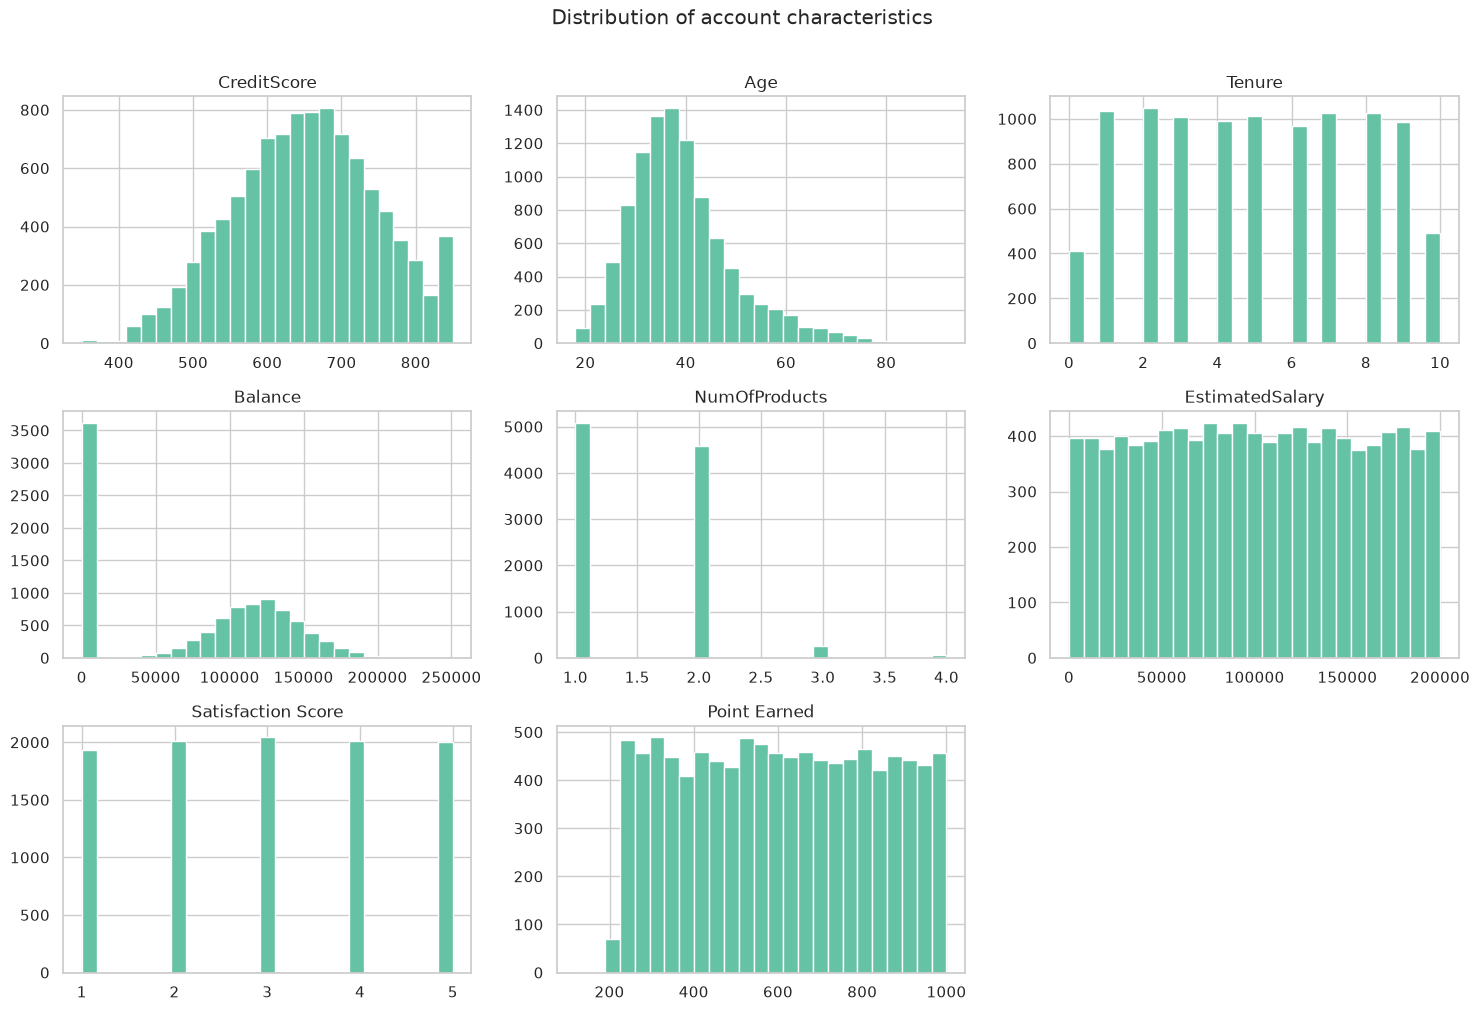

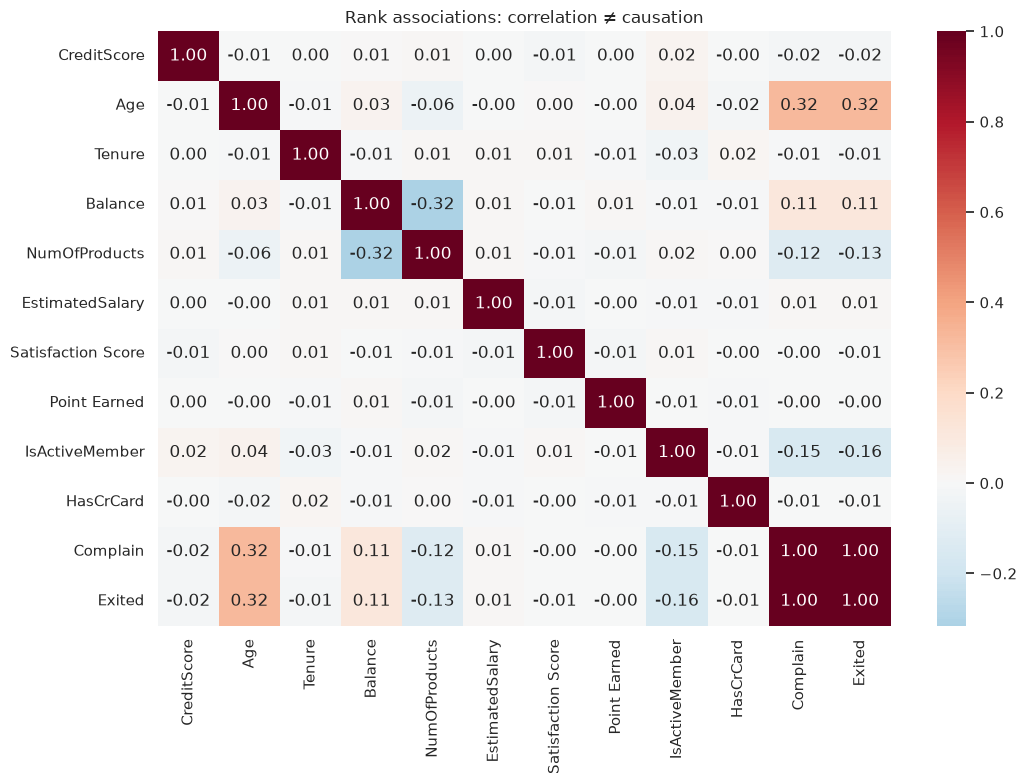

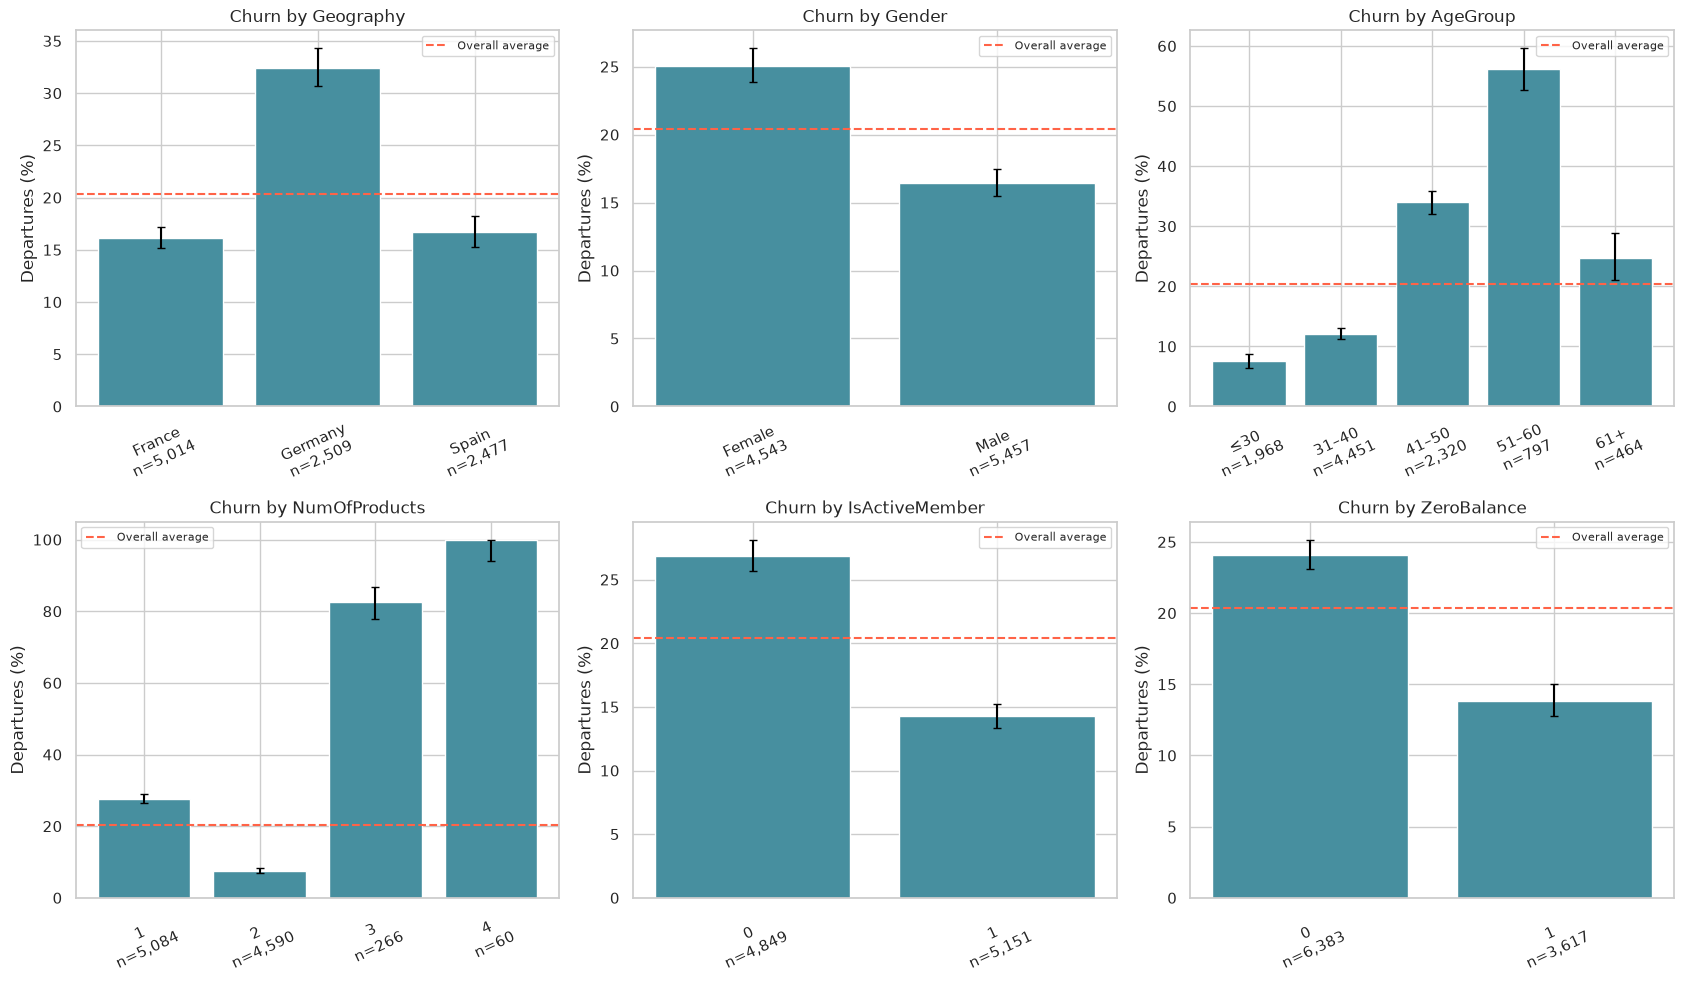

,n,departures,mean_balance,active_share,churn_pct,ci_lower,ci_upper
AgeGroup,,,,,,,
≤30,1968,148,"73,198.760",0.510,7.520,6.440,8.770
31–40,4451,539,"75,583.360",0.500,12.110,11.180,13.100
41–50,2320,788,"79,122.190",0.470,33.970,32.070,35.920
51–60,797,448,"82,401.660",0.580,56.210,52.740,59.620
61+,464,115,"75,742.600",0.810,24.780,21.070,28.910


,n,departures,mean_balance,active_share,churn_pct,ci_lower,ci_upper
NumOfProducts,,,,,,,
1,5084,1409,"98,551.870",0.500,27.710,26.500,28.960
2,4590,349,"51,879.150",0.530,7.600,6.870,8.410
3,266,220,"75,458.330",0.420,82.710,77.700,86.780
4,60,60,"93,733.140",0.480,100.000,93.980,100.000


,n,departures,mean_balance,active_share,churn_pct,ci_lower,ci_upper
Geography,,,,,,,
France,5014,811,"62,092.640",0.520,16.170,15.180,17.220
Germany,2509,814,"119,730.120",0.500,32.440,30.640,34.300
Spain,2477,413,"61,818.150",0.530,16.670,15.260,18.190


In [4]:
numeric = ["CreditScore","Age","Tenure","Balance","NumOfProducts","EstimatedSalary","Satisfaction Score","Point Earned"]
eda[numeric].hist(bins=25, figsize=(15,10), edgecolor="white")
plt.suptitle("Distribution of account characteristics", y=1.01)
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(11,8))
sns.heatmap(eda[numeric+["IsActiveMember","HasCrCard","Complain","Exited"]].corr(method="spearman"),
            cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Rank associations: correlation ≠ causation")
plt.tight_layout(); plt.show()

def plot_rates(data, key, ax):
    t=segment_table(data,key)
    x=np.arange(len(t))
    ax.bar(x,t.churn_pct,color="#478f9f")
    ax.errorbar(x,t.churn_pct,yerr=[np.maximum(0,t.churn_pct-t.ci_lower),np.maximum(0,t.ci_upper-t.churn_pct)],fmt="none",color="black",capsize=3)
    ax.set_xticks(x, [f"{v}\nn={n:,}" for v,n in zip(t.index,t.n)], rotation=25)
    ax.axhline(global_rate*100,ls="--",color="tomato",label="Overall average")
    ax.set(title=f"Churn by {key}",ylabel="Departures (%)")
    ax.legend(fontsize=8)
    return t

fig,axes=plt.subplots(2,3,figsize=(17,10))
for ax,key in zip(axes.flat,["Geography","Gender","AgeGroup","NumOfProducts","IsActiveMember","ZeroBalance"]):
    plot_rates(eda,key,ax)
plt.tight_layout(); plt.show()
for key in ["AgeGroup","NumOfProducts","Geography"]:
    display(segment_table(eda,key).round(2))

## 4. Account Usage Beyond Churn

We compare account characteristics: zero balances by country and product count, activity by age and tenure, and balance distributions among customers with positive balances. These views help identify differences in account usage alongside churn patterns.

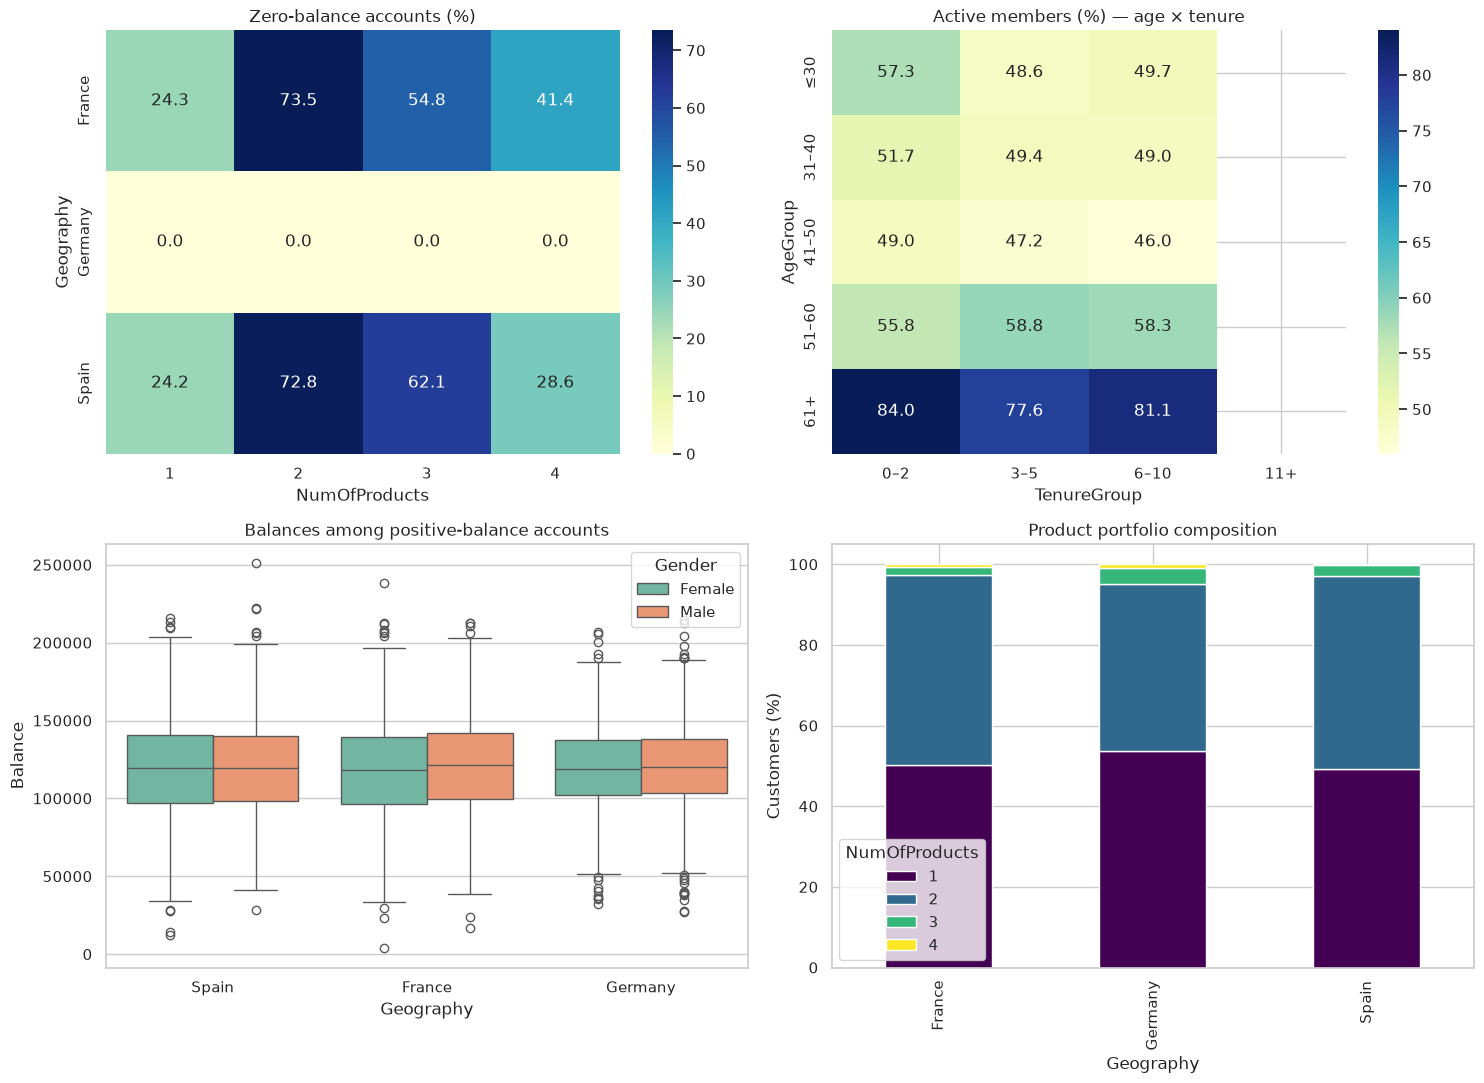

,customers,median_balance,total_balance,mean_products,median_age,median_income,balance_share_pct
EngagementSegment,,,,,,,
Active with card,3607,"95,858.370","270,390,999.890",1.540,37.000,"96,961.000",35.350
Active without card,1544,"97,258.330","120,443,299.580",1.530,38.000,"104,427.640",15.750
Inactive with card,3448,"97,995.040","264,991,173.650",1.520,37.000,"101,079.740",34.650
Inactive without card,1401,"98,459.600","109,033,419.760",1.530,37.000,"99,595.670",14.260


TenureGroup,0–2,3–5,6–10
AgeGroup,,,
≤30,454,619,895
31–40,1114,1317,2020
41–50,606,688,1026
51–60,197,243,357
61+,125,143,196


NumOfProducts,1,2,3,4
Geography,,,,
France,2514,2367,104,29
Germany,1349,1040,96,24
Spain,1221,1183,66,7


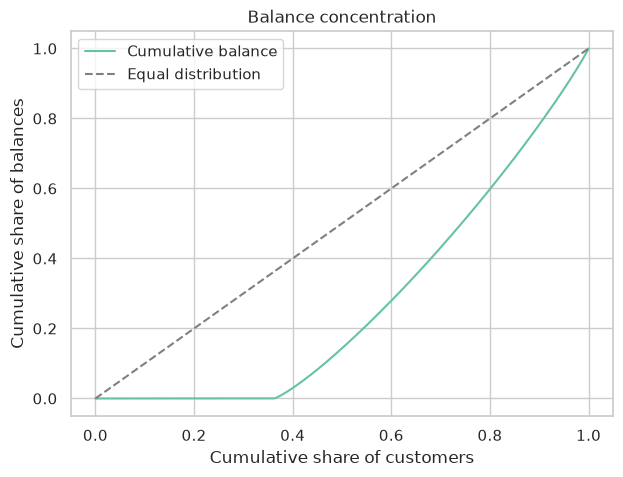

The 10% of customers with the highest balances hold **21.7%** of the total observed balance. Balance does not measure profitability.

In [5]:
fig, axes = plt.subplots(2,2,figsize=(15,11))
z = pd.crosstab(eda.Geography, eda.NumOfProducts, values=eda.ZeroBalance, aggfunc="mean")*100
sns.heatmap(z,annot=True,fmt=".1f",cmap="YlGnBu",ax=axes[0,0])
axes[0,0].set_title("Zero-balance accounts (%)")
a = pd.crosstab(eda.AgeGroup,eda.TenureGroup,values=eda.IsActiveMember,aggfunc="mean",dropna=False)*100
sns.heatmap(a,annot=True,fmt=".1f",cmap="YlGnBu",ax=axes[0,1])
axes[0,1].set_title("Active members (%) — age × tenure")
sns.boxplot(data=eda[eda.Balance>0],x="Geography",y="Balance",hue="Gender",ax=axes[1,0])
axes[1,0].set_title("Balances among positive-balance accounts")
products=pd.crosstab(eda.Geography,eda.NumOfProducts,normalize="index")*100
products.plot.bar(stacked=True,ax=axes[1,1],colormap="viridis")
axes[1,1].set(title="Product portfolio composition",ylabel="Customers (%)")
plt.tight_layout(); plt.show()
profile=eda.groupby("EngagementSegment",observed=True).agg(
    customers=("CustomerId","size"),median_balance=("Balance","median"),
    total_balance=("Balance","sum"),mean_products=("NumOfProducts","mean"),
    median_age=("Age","median"),median_income=("EstimatedSalary","median"))
profile["balance_share_pct"] = profile.total_balance / eda.Balance.sum()*100
display(profile.round(2))
display(pd.crosstab(eda.AgeGroup, eda.TenureGroup))
display(pd.crosstab(eda.Geography, eda.NumOfProducts))
# Balance concentration describes holdings, not bank revenue or profit.
sorted_bal=np.sort(eda.Balance.to_numpy()); cum=np.cumsum(sorted_bal)/sorted_bal.sum()
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(np.linspace(0,1,len(cum)+1),np.r_[0,cum],label="Cumulative balance")
ax.plot([0,1],[0,1],"--",color="gray",label="Equal distribution")
ax.set(xlabel="Cumulative share of customers",ylabel="Cumulative share of balances",title="Balance concentration")
ax.legend(); plt.show()
top10=eda.Balance.nlargest(int(np.ceil(len(eda)*.1))).sum()/eda.Balance.sum()
display(Markdown(f"The 10% of customers with the highest balances hold **{top10:.1%}** of the total observed balance. Balance does not measure profitability."))

## 5. Interactions: Profiles Hidden by Averages

Product count may have a nonlinear relationship with churn. We examine product holdings and activity together, followed by age and activity. Read the churn heatmaps alongside the sample sizes: an extreme rate in a small group is insufficient evidence for a campaign decision.

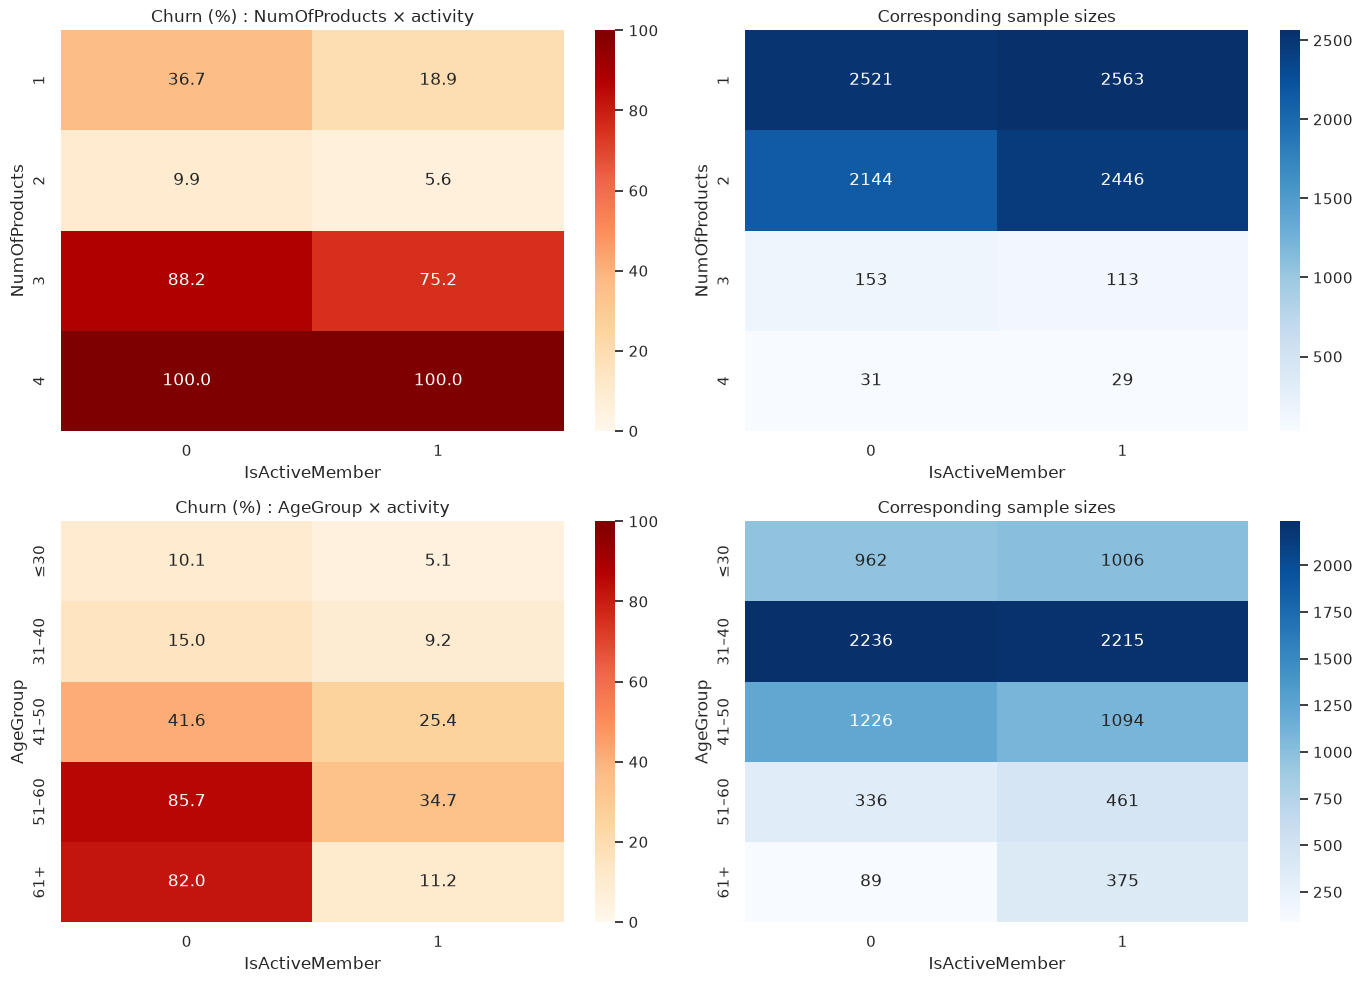

n  departures  mean_balance  active_share  \
Geography EngagementSegment                                                     
Germany   Inactive with card      918         378   120,272.500         0.000   
France    Inactive with card     1717         375    62,697.180         0.000   
Germany   Active with card        873         199   120,408.730         1.000   
France    Active with card       1826         195    59,540.870         1.000   
Spain     Inactive with card      813         190    57,724.420         0.000   
Germany   Inactive without card   343         140   117,752.770         0.000   
France    Inactive without card   706         138    65,327.450         0.000   
          Active without card     765         103    63,841.330         1.000   
Germany   Active without card     375          97   118,631.180         1.000   
Spain     Active with card        908          88    62,282.560         1.000   
          Inactive without card   352          82    63,985.910         0.000   
          Active without card     404          53    67,123.750         1.000   

                                 churn_pct  ci_lower  ci_upper  
Geography EngagementSegment                                     
Germany   Inactive with card        41.180    38.040    44.390  
France    Inactive with card        21.840    19.950    23.860  
Germany   Active with card          22.790    20.130    25.690  
France    Active with card          10.680     9.340    12.180  
Spain     Inactive with card        23.370    20.590    26.400  
Germany   Inactive without card     40.820    35.740    46.090  
France    Inactive without card     19.550    16.790    22.630  
          Active without card       13.460    11.230    16.070  
Germany   Active without card       25.870    21.690    30.530  
Spain     Active with card           9.690     7.930    11.790  
          Inactive without card     23.300    19.180    27.990  
          Active without card       13.120    10.170    16.760

n  mean_tenure  median_tenure
Geography Gender                                  
France    Female  2261        4.950          5.000
          Male    2753        5.049          5.000
Germany   Female  1193        4.966          5.000
          Male    1316        5.050          5.000
Spain     Female  1089        5.000          5.000
          Male    1388        5.058          5.000

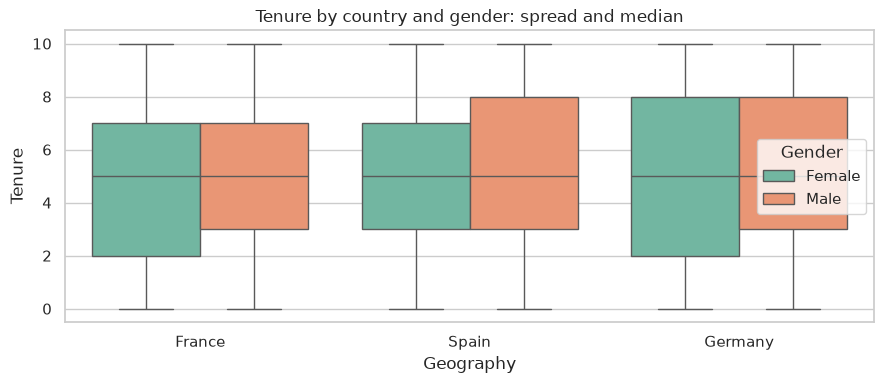

In [6]:
fig, axes=plt.subplots(2,2,figsize=(14,10))
for row,key in enumerate(["NumOfProducts","AgeGroup"]):
    t=segment_table(eda,[key,"IsActiveMember"]).reset_index()
    sns.heatmap(t.pivot(index=key,columns="IsActiveMember",values="churn_pct"),annot=True,fmt=".1f",vmin=0,vmax=100,cmap="OrRd",ax=axes[row,0])
    axes[row,0].set_title(f"Churn (%) : {key} × activity")
    sns.heatmap(t.pivot(index=key,columns="IsActiveMember",values="n"),annot=True,fmt=".0f",cmap="Blues",ax=axes[row,1])
    axes[row,1].set_title("Corresponding sample sizes")
plt.tight_layout(); plt.show()
# Rank segments by departures and associated balances; these figures do not measure financial losses.
segments=segment_table(eda,["Geography","EngagementSegment"])
display(segments.sort_values("departures",ascending=False).round(2))
geo_gender=eda.groupby(["Geography","Gender"]).agg(n=("Tenure","size"),mean_tenure=("Tenure","mean"),median_tenure=("Tenure","median"))
display(geo_gender)
fig,ax=plt.subplots(figsize=(9,4))
sns.boxplot(data=eda,x="Geography",y="Tenure",hue="Gender",ax=ax)
ax.set_title("Tenure by country and gender: spread and median")
plt.tight_layout();plt.show()

## 6. Complaints, Satisfaction, and Loyalty: Target Leakage Review

A strong association between complaints and departure may be useful, but complaints could also have been recorded at the time of departure. Without dates, we cannot distinguish these explanations. `Complain` is **excluded from the main model**, along with other service fields whose timing is unknown. A separate experiment illustrates its effect.

Every retained feature must also be available before departure in a real application. This notebook evaluates a statistical workflow on cross-sectional data; it does not validate forecasting over time.

Agreement between Complain and Exited: 99.86%


Exited,0,1,All
Complain,,,
0,7952,4,7956
1,10,2034,2044
All,7962,2038,10000


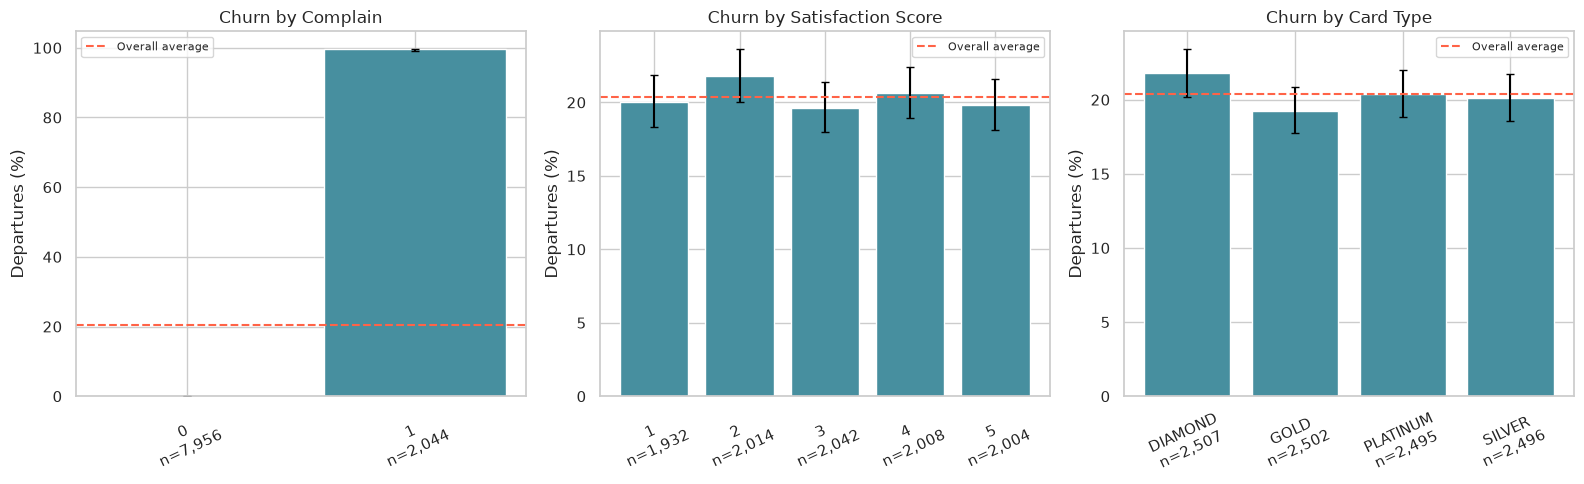

,n,median_points,mean_satisfaction,median_balance,churn
Card Type,,,,,
DIAMOND,2507,603.000,2.994,"99,844.680",0.218
GOLD,2502,603.000,3.044,"97,070.055",0.193
PLATINUM,2495,607.000,3.010,"96,939.060",0.204
SILVER,2496,604.000,3.007,"92,871.075",0.201


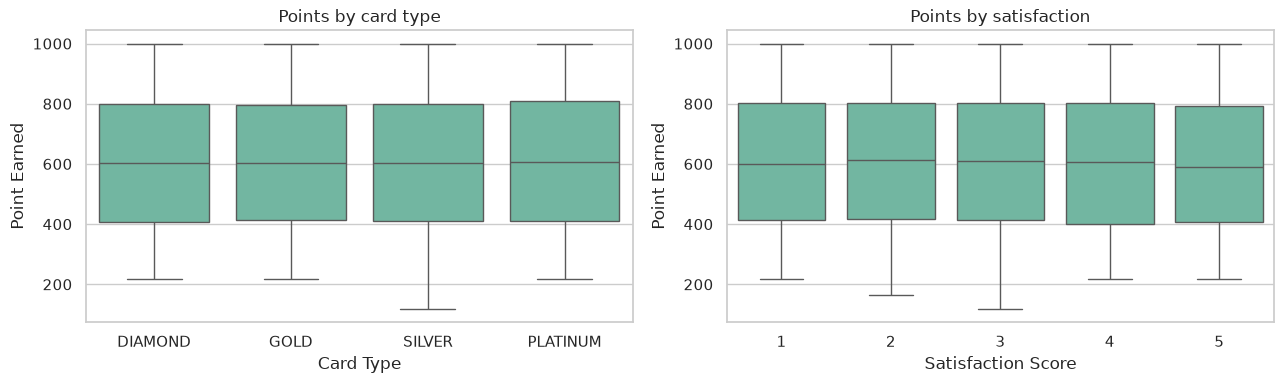

Interpret differences in satisfaction or points alongside their spread. No visible association in this sample does not rule out an effect in another population.

In [7]:
display(pd.crosstab(eda.Complain,eda.Exited,margins=True))
print(f"Agreement between Complain and Exited: {(eda.Complain==eda.Exited).mean():.2%}")
fig,axes=plt.subplots(1,3,figsize=(16,5))
for ax,key in zip(axes,["Complain","Satisfaction Score","Card Type"]):
    plot_rates(eda,key,ax)
plt.tight_layout();plt.show()
card_profile=eda.groupby("Card Type").agg(n=("Exited","size"),median_points=("Point Earned","median"),
    mean_satisfaction=("Satisfaction Score","mean"),median_balance=("Balance","median"),churn=("Exited","mean"))
display(card_profile)
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.boxplot(data=eda,x="Card Type",y="Point Earned",ax=axes[0])
sns.boxplot(data=eda,x="Satisfaction Score",y="Point Earned",ax=axes[1])
axes[0].set_title("Points by card type"); axes[1].set_title("Points by satisfaction")
plt.tight_layout(); plt.show()
md_note = "Interpret differences in satisfaction or points alongside their spread. No visible association in this sample does not rule out an effect in another population."
display(Markdown(md_note))

## 7. Logistic Regression: Preventing Training Leakage

The stratified split allocates **60% to training, 20% to validation, and 20% to testing**. Imputation, scaling, and encoding are fitted within each training fold. The test set is reserved for the final evaluation.

Cross-validation on the training set compares two variants: original features and an expanded feature set with squared age, interactions, engagement groups, and ratios. Product count is categorical to capture its nonlinear relationship with churn. `C` controls regularization. Selection minimizes log loss to prioritize probability quality. The operational threshold is selected on the validation set without consulting the test set.

Identifiers, `Complain`, `Satisfaction Score`, `Card Type`, `Point Earned`, and the points ratio are excluded from the main model. Geography and gender are retained for this study; operational use requires an appropriate policy and a fairness review.

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    precision_score, recall_score, f1_score, accuracy_score, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.calibration import CalibrationDisplay

train_idx, test_idx = train_test_split(df.index,test_size=.2,stratify=df.Exited,random_state=SEED)
train_idx, val_idx = train_test_split(train_idx,test_size=.25,stratify=df.loc[train_idx,"Exited"],random_state=SEED)
y_train=df.loc[train_idx,"Exited"]; y_val=df.loc[val_idx,"Exited"]; y_test=df.loc[test_idx,"Exited"]
display(pd.DataFrame({"n":[len(train_idx),len(val_idx),len(test_idx)],
    "churn":[y_train.mean(),y_val.mean(),y_test.mean()]},index=["train","validation","test"]))
base_num=["CreditScore","Age","Tenure","Balance","HasCrCard","IsActiveMember","EstimatedSalary"]
base_cat=["Geography","Gender","NumOfProducts"]
extra_num=["ZeroBalance","BalanceSalaryRatio","BalancePerProduct","InactivePositiveBalance","AgeSquared","AgeInactive"]
extra_cat=["AgeGroup","TenureGroup","EngagementSegment"]

def make_pipeline(num,cat):
    prep=ColumnTransformer([
        ("num",Pipeline([("imputer",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),
        ("cat",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                         ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first"))]),cat)])
    return Pipeline([("prep",prep),("model",LogisticRegression(max_iter=4000,random_state=SEED))])
cv=StratifiedKFold(5,shuffle=True,random_state=SEED)
searches={}; rows=[]
for name,num,cat in [("Original",base_num,base_cat),("Expanded",base_num+extra_num,base_cat+extra_cat)]:
    search=GridSearchCV(make_pipeline(num,cat),{"model__C":[.01,.1,1,10]},
        scoring={"logloss":"neg_log_loss","roc_auc":"roc_auc","ap":"average_precision"},refit="logloss",cv=cv,n_jobs=1)
    search.fit(eda.loc[train_idx],y_train)
    searches[name]=search; i=search.best_index_
    rows.append({"variant":name,"C":search.best_params_["model__C"],
        "logloss_cv":-search.cv_results_["mean_test_logloss"][i],
        "logloss_std":search.cv_results_["std_test_logloss"][i],
        "roc_auc_cv":search.cv_results_["mean_test_roc_auc"][i],
        "AP_cv":search.cv_results_["mean_test_ap"][i]})
comparison=pd.DataFrame(rows).sort_values("logloss_cv")
display(comparison)
chosen_name=comparison.iloc[0].variant
model=searches[chosen_name].best_estimator_
print("Variant selected using cross-validation only:",chosen_name)

Variant selected using cross-validation only: Expanded


,n,churn
train,6000,0.204
validation,2000,0.203
test,2000,0.204


,variant,C,logloss_cv,logloss_std,roc_auc_cv,AP_cv
1,Expanded,10,0.350,0.022,0.852,0.677
0,Original,10,0.377,0.019,0.828,0.615


### Sensitivity to `Complain`: Validation Set Only

This comparison uses exactly the same training and validation customers. A substantial improvement with complaints would strengthen the case for checking when they were recorded; it would not, by itself, prove leakage. The main model continues to exclude this field.

In [9]:
selected_num = base_num + (extra_num if chosen_name=="Expanded" else [])
selected_cat = base_cat + (extra_cat if chosen_name=="Expanded" else [])
sensitive=make_pipeline(selected_num+["Complain"],selected_cat)
sensitive.set_params(model__C=searches[chosen_name].best_params_["model__C"])
sensitive.fit(eda.loc[train_idx],y_train)
sensitivity=[]
for label,est in [("Main model without complaints",model),("Diagnostic model with complaints",sensitive)]:
    pv=est.predict_proba(eda.loc[val_idx])[:,1]
    sensitivity.append({"model":label,"AUC_validation":roc_auc_score(y_val,pv),"logloss_validation":log_loss(y_val,pv)})
display(pd.DataFrame(sensitivity))
p_val=model.predict_proba(eda.loc[val_idx])[:,1]
pr,re,thresholds=precision_recall_curve(y_val,p_val)
f1s=2*pr[:-1]*re[:-1]/np.maximum(pr[:-1]+re[:-1],1e-12)
threshold=float(thresholds[np.argmax(f1s)])
print(f"Threshold selected by validation F1: {threshold:.3f}")
print("This threshold does not optimize business value: contact costs, churn costs, and offer effectiveness are unavailable.")

Threshold selected by validation F1: 0.355
This threshold does not optimize business value: contact costs, churn costs, and offer effectiveness are unavailable.


,model,AUC_validation,logloss_validation
0,Main model without complaints,0.853,0.346
1,Diagnostic model with complaints,1.000,0.009


## 8. Final Evaluation on the Held-Out Test Set

Accuracy alone can be misleading when most customers stay. We report ROC-AUC, average precision (AP, compared with prevalence), precision, recall, F1, log loss, and the Brier score. Calibration assesses whether predicted probabilities match observed frequencies. The model remains fitted on the 60% training split so that the selected threshold remains applicable.

Observed test rate: 20.40% ; mean predicted rate: 21.35%
The bootstrap interval does not capture retraining variability or future population shifts.


,ROC_AUC,AP,log_loss,Brier,accuracy,precision,recall,F1
Training prevalence baseline,0.500,0.204,0.506,0.162,0.796,0.000,0.000,0.000
"Logistic regression, threshold 0.5",0.866,0.709,0.334,0.101,0.864,0.756,0.493,0.596
"Logistic regression, validation threshold",0.866,0.709,0.334,0.101,0.852,0.640,0.623,0.631


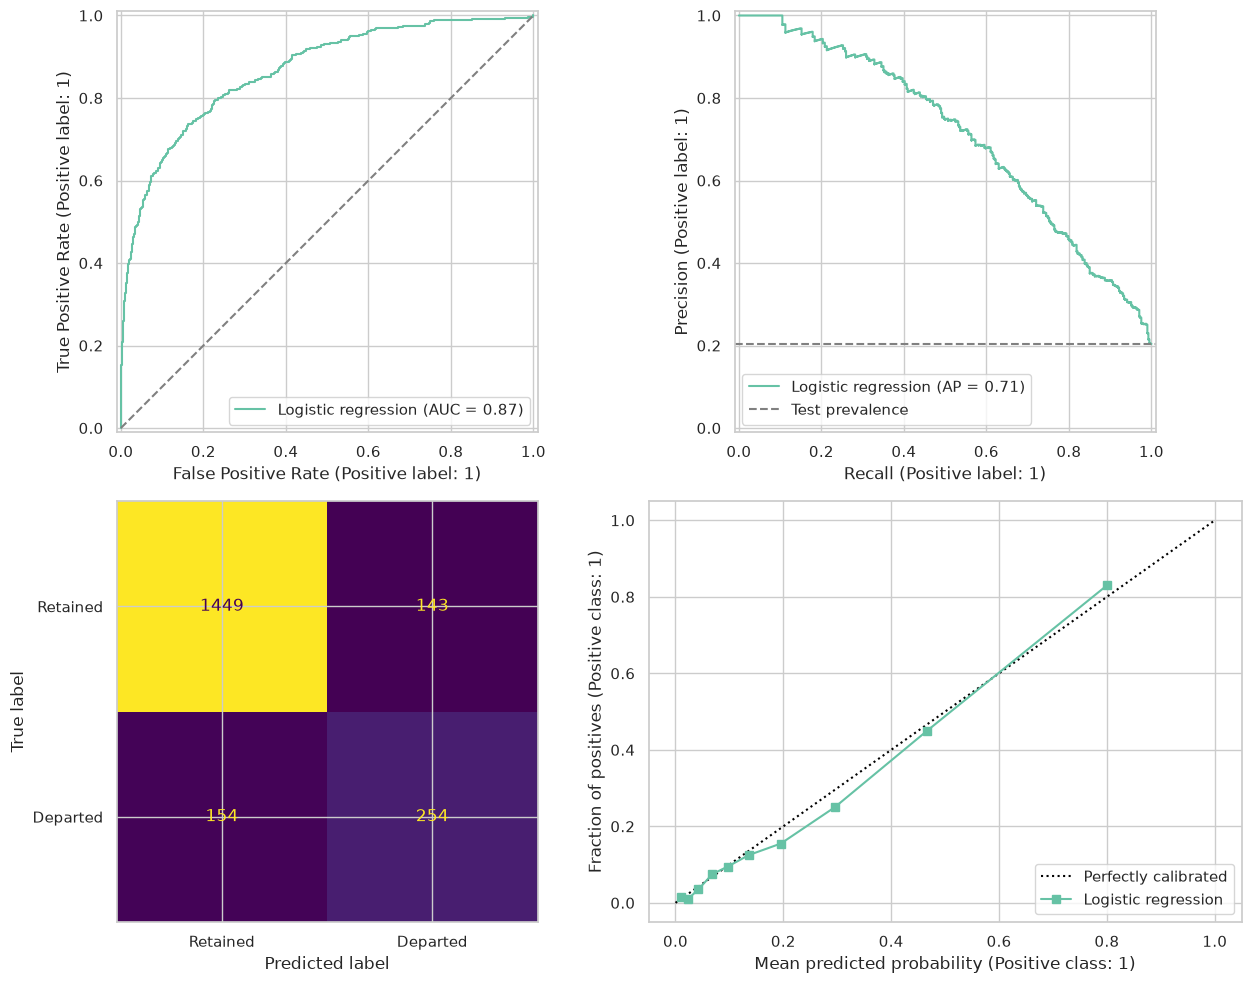

,Bootstrap CI 2.5%,97.5%
ROC-AUC,0.847,0.887
Predicted minus observed rate,-0.004,0.024


In [10]:
p_test=model.predict_proba(eda.loc[test_idx])[:,1]
dummy=DummyClassifier(strategy="prior").fit(eda.loc[train_idx],y_train)
p_dummy=dummy.predict_proba(eda.loc[test_idx])[:,1]
def evaluate(y,p,t):
    pred=(p>=t).astype(int)
    return {"ROC_AUC":roc_auc_score(y,p),"AP":average_precision_score(y,p),
        "log_loss":log_loss(y,p),"Brier":brier_score_loss(y,p),"accuracy":accuracy_score(y,pred),
        "precision":precision_score(y,pred,zero_division=0),"recall":recall_score(y,pred),"F1":f1_score(y,pred)}
results=pd.DataFrame([evaluate(y_test,p_dummy,.5),evaluate(y_test,p_test,.5),evaluate(y_test,p_test,threshold)],
    index=["Training prevalence baseline","Logistic regression, threshold 0.5","Logistic regression, validation threshold"])
display(results)
fig,axes=plt.subplots(2,2,figsize=(13,10))
RocCurveDisplay.from_predictions(y_test,p_test,ax=axes[0,0],name="Logistic regression")
axes[0,0].plot([0,1],[0,1],"--",color="gray")
PrecisionRecallDisplay.from_predictions(y_test,p_test,ax=axes[0,1],name="Logistic regression")
axes[0,1].axhline(y_test.mean(),ls="--",color="gray",label="Test prevalence"); axes[0,1].legend()
ConfusionMatrixDisplay.from_predictions(y_test,p_test>=threshold,display_labels=["Retained","Departed"],ax=axes[1,0],colorbar=False)
CalibrationDisplay.from_predictions(y_test,p_test,n_bins=10,strategy="quantile",ax=axes[1,1],name="Logistic regression")
plt.tight_layout();plt.show()
# Estimate uncertainty for the fitted model by bootstrapping test customers.
rng=np.random.default_rng(SEED); boot=[]
y_arr=y_test.to_numpy()
for _ in range(500):
    ix=rng.integers(0,len(y_arr),len(y_arr))
    if len(np.unique(y_arr[ix]))<2: continue
    boot.append([roc_auc_score(y_arr[ix],p_test[ix]),p_test[ix].mean()-y_arr[ix].mean()])
boot=np.array(boot)
display(pd.DataFrame(np.quantile(boot,[.025,.975],axis=0).T,
    index=["ROC-AUC","Predicted minus observed rate"],columns=["Bootstrap CI 2.5%","97.5%"]))
print(f"Observed test rate: {y_test.mean():.2%} ; mean predicted rate: {p_test.mean():.2%}")
print("The bootstrap interval does not capture retraining variability or future population shifts.")

## 9. Model Interpretation, Risk Concentration, and Group Differences

Coefficients represent adjusted associations, not causes. Numerical features are standardized, so their odds ratios correspond to a one-standard-deviation increase. Categories are compared with the encoder's reference category. Correlated derived features make individual coefficients harder to interpret.

Risk deciles simulate a limited contact capacity. The share of departures captured does not measure achieved retention or establish profitability.

These descriptive differences come from one test set and do not establish fairness.


,variable,coefficient,odds_ratio
16,cat__NumOfProducts_2,-2.581,0.076
11,num__AgeSquared,-2.331,0.097
9,num__BalancePerProduct,-1.430,0.239
15,cat__Gender_Male,-0.546,0.579
27,cat__EngagementSegment_Inactive without card,-0.467,0.627
26,cat__EngagementSegment_Inactive with card,-0.264,0.768
2,num__Tenure,-0.085,0.918
4,num__HasCrCard,-0.066,0.936
10,num__InactivePositiveBalance,-0.065,0.937
0,num__CreditScore,-0.054,0.947


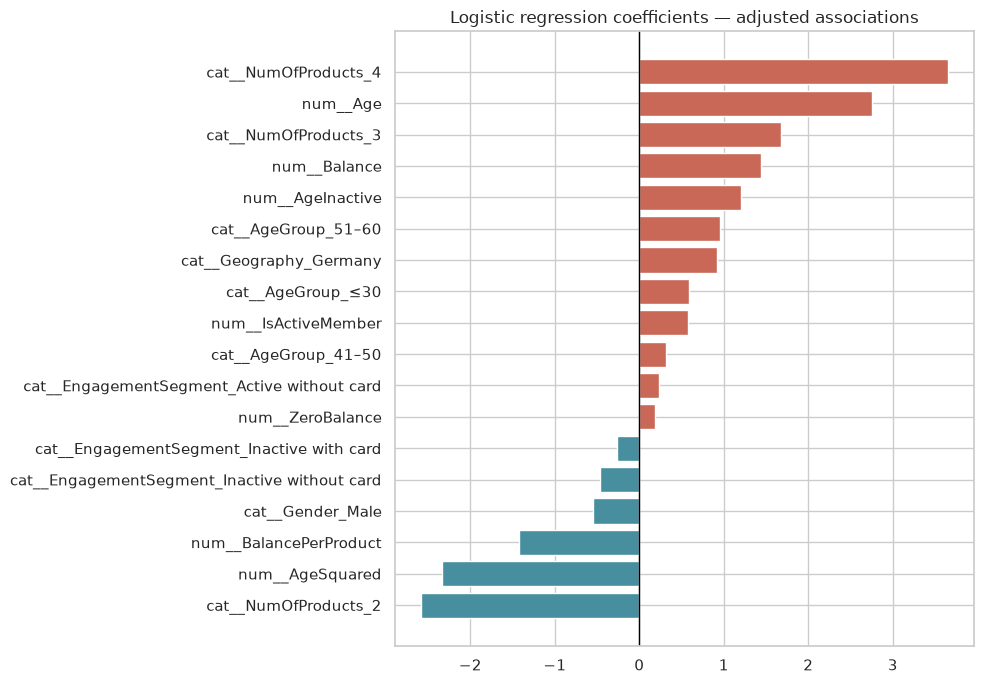

,n,departures,observed_rate,predicted_rate,lift,cumulative_departure_share
risk_decile,,,,,,
1,200,166,0.830,0.800,4.069,0.407
2,200,90,0.450,0.467,2.206,0.627
3,200,50,0.250,0.295,1.225,0.750
4,200,31,0.155,0.195,0.760,0.826
5,200,25,0.125,0.136,0.613,0.887
6,200,19,0.095,0.097,0.466,0.934
7,200,15,0.075,0.068,0.368,0.971
8,200,7,0.035,0.042,0.172,0.988
9,200,2,0.010,0.023,0.049,0.993


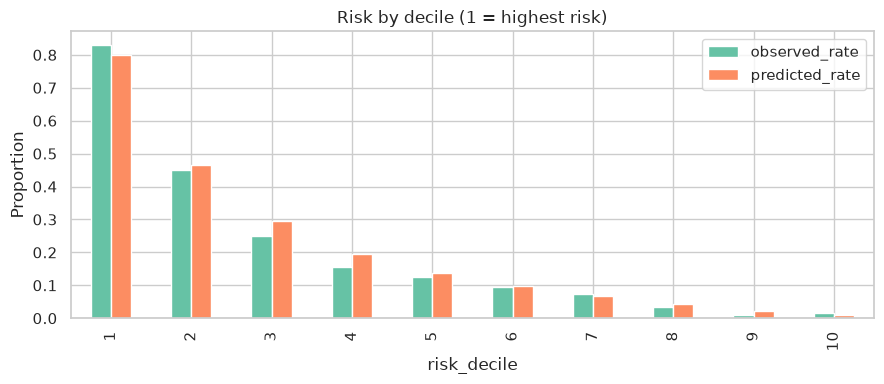

,n,observed_rate,predicted_rate,recall,false_positive_rate
France,"1,011.000",0.173,0.172,0.571,0.071
Germany,499.000,0.301,0.333,0.727,0.163
Spain,490.000,0.169,0.178,0.542,0.066


,n,observed_rate,predicted_rate,recall,false_positive_rate
Female,932.000,0.250,0.260,0.700,0.130
Male,"1,068.000",0.164,0.173,0.520,0.058


,n,observed_rate,predicted_rate,recall,false_positive_rate
≤30,386.000,0.065,0.065,0.080,0.003
31–40,870.000,0.108,0.132,0.245,0.028
41–50,506.000,0.354,0.359,0.743,0.275
51–60,150.000,0.587,0.556,0.932,0.419
61+,88.000,0.250,0.256,0.636,0.061


,CustomerId,churn_probability,alert
6176,15604146,0.107,0
7072,15775750,0.132,0
877,15800228,0.038,0
6539,15749328,0.147,0
5190,15579548,0.022,0
9727,15807728,0.511,1
6561,15650538,0.784,1
4711,15758831,0.171,0
9099,15768881,0.010,0
5975,15758039,0.040,0


In [11]:
names=model.named_steps["prep"].get_feature_names_out()
coef=pd.DataFrame({"variable":names,"coefficient":model.named_steps["model"].coef_[0]})
coef["odds_ratio"]=np.exp(coef.coefficient)
display(coef.sort_values("coefficient"))
strong=coef.loc[coef.coefficient.abs().nlargest(18).index].sort_values("coefficient")
fig,ax=plt.subplots(figsize=(10,7))
ax.barh(strong.variable,strong.coefficient,color=np.where(strong.coefficient>0,"#c96857","#478f9f"))
ax.axvline(0,color="black",lw=1); ax.set_title("Logistic regression coefficients — adjusted associations")
plt.tight_layout();plt.show()
scored=eda.loc[test_idx,["CustomerId","Geography","Gender","AgeGroup","Balance","Exited"]].copy()
scored["churn_probability"]=p_test
scored["alert"]=(p_test>=threshold).astype(int)
scored["risk_decile"]=pd.qcut(scored.churn_probability.rank(method="first",ascending=False),10,labels=range(1,11))
deciles=scored.groupby("risk_decile",observed=True).agg(n=("Exited","size"),departures=("Exited","sum"),
    observed_rate=("Exited","mean"),predicted_rate=("churn_probability","mean"))
deciles["lift"]=deciles.observed_rate/y_test.mean()
deciles["cumulative_departure_share"]=deciles.departures.cumsum()/deciles.departures.sum()
display(deciles)
fig,ax=plt.subplots(figsize=(9,4))
deciles[["observed_rate","predicted_rate"]].plot.bar(ax=ax)
ax.set(title="Risk by decile (1 = highest risk)",ylabel="Proportion")
plt.tight_layout();plt.show()

def group_performance(g):
    return pd.Series({"n":len(g),"observed_rate":g.Exited.mean(),"predicted_rate":g.churn_probability.mean(),
        "recall":recall_score(g.Exited,g.alert,zero_division=0),
        "false_positive_rate":((g.alert==1)&(g.Exited==0)).sum()/max((g.Exited==0).sum(),1)})
for key in ["Geography","Gender","AgeGroup"]:
    rows=[]
    for label,g in scored.groupby(key,observed=True):
        row=group_performance(g);row.name=label;rows.append(row)
    display(pd.DataFrame(rows))
print("These descriptive differences come from one test set and do not establish fairness.")
display(scored[["CustomerId","churn_probability","alert"]].head(10))

## 10. Findings and Next Steps

The figures below are calculated from the preceding results. Segment patterns describe associations within this dataset and do not establish causality.

In [12]:
product_stats=segment_table(eda,"NumOfProducts")
zero_geo=eda.groupby("Geography").ZeroBalance.mean()
activity=segment_table(eda,"IsActiveMember")
positive_inactive=eda[(eda.IsActiveMember==0)&(eda.Balance>0)]
summary=f"""
- **Overall churn: {global_rate:.2%}** across {len(df):,} customers.
- **Product holdings:** churn by product count: {', '.join(f'{k} product(s): {r.churn_pct:.1f}% (n={int(r.n)})' for k,r in product_stats.iterrows())}. A linear comparison would hide these differences. Check product types and opening dates before planning a campaign.
- **Activity:** churn is {activity.loc[0,'churn_pct']:.1f}% among inactive customers and {activity.loc[1,'churn_pct']:.1f}% among active customers. The data does not establish whether inactivity precedes departure.
- **Account usage:** {eda.ZeroBalance.mean():.1%} of accounts have zero balances. By country: {', '.join(f'{k}: {v:.1%}' for k,v in zero_geo.items())}. Review account types and transactions before interpreting these customers as disengaged.
- **Inactive customers with balances:** {len(positive_inactive):,} inactive customers have positive balances and hold {positive_inactive.Balance.sum()/eda.Balance.sum():.1%} of the total balance. Their account usage warrants investigation; balances do not measure bank revenue.
- **Feature reliability:** complaints and departure agree in {(eda.Complain==eda.Exited).mean():.2%} of cases. Verify timing before using complaints in production.
- **Selected regression:** {chosen_name.lower()} variant, test ROC-AUC {roc_auc_score(y_test,p_test):.3f}, AP {average_precision_score(y_test,p_test):.3f}, Brier {brier_score_loss(y_test,p_test):.3f}. Mean predicted rate: {p_test.mean():.2%}; observed rate: {y_test.mean():.2%}.
- **Prioritization:** the highest-risk decile contains {deciles.iloc[0].cumulative_departure_share:.1%} of test departures, with a lift of {deciles.iloc[0]['lift']:.2f}. This measures ranking performance, not prevented departures.
"""
display(Markdown(summary))



- **Overall churn: 20.38%** across 10,000 customers.
- **Product holdings:** churn by product count: 1 product(s): 27.7% (n=5084), 2 product(s): 7.6% (n=4590), 3 product(s): 82.7% (n=266), 4 product(s): 100.0% (n=60). A linear comparison would hide these differences. Check product types and opening dates before planning a campaign.
- **Activity:** churn is 26.9% among inactive customers and 14.3% among active customers. The data does not establish whether inactivity precedes departure.
- **Account usage:** 36.2% of accounts have zero balances. By country: France: 48.2%, Germany: 0.0%, Spain: 48.4%. Review account types and transactions before interpreting these customers as disengaged.
- **Inactive customers with balances:** 3,105 inactive customers have positive balances and hold 48.9% of the total balance. Their account usage warrants investigation; balances do not measure bank revenue.
- **Feature reliability:** complaints and departure agree in 99.86% of cases. Verify timing before using complaints in production.
- **Selected regression:** expanded variant, test ROC-AUC 0.866, AP 0.709, Brier 0.101. Mean predicted rate: 21.35%; observed rate: 20.40%.
- **Prioritization:** the highest-risk decile contains 40.7% of test departures, with a lift of 4.07. This measures ranking performance, not prevented departures.


### Recommendations and Limitations

1. **Document timing:** Record observation dates, departure dates, the definition of activity, the prediction horizon, and when each field becomes available. Then validate on a future period.
2. **Understand account usage:** Review zero-balance accounts by product and country. Examine transactions, fees, product changes, and channels to distinguish secondary accounts from disengagement.
3. **Test interventions:** Trial support for inactive customers or high-risk portfolios with a control group. Measure incremental retention and its cost.
4. **Monitor small segments and bias:** Report sample sizes and track calibration and errors by group. Review the role of country, gender, and age before operational use.
5. **Separate association from causality:** Product holdings, age, and satisfaction are not established causes of departure here. The model and findings remain specific to this dataset.

**Reproducibility:** Run the cells in order. Dependencies: pandas, NumPy, Matplotlib, seaborn, scikit-learn, and a Jupyter Python kernel. No network requests or additional external data files are required.